# 0.1. Data Load and Pre-proces

## Mount drive and unzip

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [ ]:
!unzip "/content/drive/MyDrive/CVI_Spark/spark-2024-train-val.zip" -d "/content/spark-2024-train-val"

Streaming output truncated to the last 5000 lines.
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_04811_layer.jpg  
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_06480_layer.jpg  
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_05998_layer.jpg  
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_07165_layer.jpg  
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_07954_layer.jpg  
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_07679_layer.jpg  
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_02430_layer.jpg  
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_05817_layer.jpg  
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_05210_layer.jpg  
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_08618_layer.jpg  
  inflating: /content/spark-2024-train-val/mask/Smart1/train/image_08332_layer.jpg  
  inflating: /

In [ ]:

### only if you got utf error
import locale
locale.getpreferredencoding = lambda: "UTF-8"

## Basic imports

In [ ]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab.patches import cv2_imshow # for visualization instead of cv2.imageshow
import random

# 0.2. Preprocessing and Load Dataset

In [ ]:
from ast import literal_eval
import os
import matplotlib.pyplot as plt
from skimage import io , img_as_uint
import pandas as pd
import matplotlib.patches as mpatches
from torch.utils.data import Dataset # Added this line


def process_labels(labels_dir,split):
    path = os.path.join(labels_dir, f"{split}.csv")
    labels = pd.read_csv(path)
    return labels



class SPARKDataset:

    """ Class for dataset inspection: easily accessing single images, and corresponding ground truth pose data. """

    def __init__(self, class_map, root_dir='./data',split='train'):
        self.root_dir = os.path.join(root_dir)
        self.labels = process_labels(root_dir,split)
        self.class_map = class_map
        self.split = split

    def get_sample(self, i=0):

        """ Loading image as PIL image. """

        sat_name = self.labels.iloc[i]['Class']
        img_name = self.labels.iloc[i]['Image name']
        mask_name = self.labels.iloc[i]['Mask name']
        bbox = self.labels.iloc[i]['Bounding box']

        image_file = f'{self.root_dir}/images/{sat_name}/{self.split}/{img_name}'
        mask_file = f'{self.root_dir}/mask/{sat_name}/{self.split}/{mask_name}'

        bbox = literal_eval(bbox)
        image = io.imread(image_file)
        mask = io.imread(mask_file)


        return {"img": image , "mask":mask, "bbox":bbox, "class":self.class_map[sat_name]}


    def visualize(self, i, size=(15, 15), ax=None, mask_visualize=False):
        """Visualizing image, with ground truth pose and optional mask overlay."""

        if ax is None:
            ax = plt.gca()

        sample = self.get_sample(i)
        image = sample['img']
        mask = sample['mask']
        img_class = sample['class']
        bbox = sample['bbox']
        x_min, y_min, x_max, y_max = bbox

        if mask_visualize:
            ax.imshow(image, vmin=0, vmax=255)
            ax.imshow(mask, alpha=0.5)  # Add overlay with semi-transparent mask

        else:
            ax.imshow(image, vmin=0, vmax=255)

        # Adjust rectangle creation to match the new bbox format (Pascal VOC format)
        rect = mpatches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                fill=False, edgecolor='red', linewidth=2)
        point1 = mpatches.Circle((x_min, y_min), radius=5, color='green')
        point2 = mpatches.Circle((x_max, y_max), radius=5, color='blue')
        ax.add_patch(point1)
        ax.add_patch(point2)
        ax.add_patch(rect)

        label = f"{list(self.class_map.keys())[list(self.class_map.values()).index(img_class)]}"

        # Adjust text placement to reflect the new coordinate system
        ax.text(x_min, y_min-50, label, color='white', fontsize=10, verticalalignment='top')

        ax.set_axis_off()


class PyTorchSPARKDataset(Dataset):
    """PyTorch Dataset class for SPARK dataset."""

    def __init__(self, class_map, root_dir='./data', split='train', transform=None):
        self.root_dir = os.path.join(root_dir)
        self.labels = process_labels(root_dir, split)
        self.class_map = class_map
        self.split = split
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        sat_name = self.labels.iloc[idx]['Class']
        img_name = self.labels.iloc[idx]['Image name']
        mask_name = self.labels.iloc[idx]['Mask name']
        bbox = literal_eval(self.labels.iloc[idx]['Bounding box'])

        image_file = f'{self.root_dir}/images/{sat_name}/{self.split}/{img_name}'
        mask_file = f'{self.root_dir}/mask/{sat_name}/{self.split}/{mask_name}'

        image = io.imread(image_file)
        mask = io.imread(mask_file)

        sample = {"img": image, "mask": mask, "bbox": bbox, "class": self.class_map[sat_name]}

        if self.transform:
            sample = self.transform(sample)

        # Convert your image and mask to PyTorch tensors
        sample['img'] = transforms.ToTensor()(sample['img'])
        sample['mask'] = transforms.ToTensor()(sample['mask'])
        sample['bbox'] = torch.tensor(sample['bbox'])

        # Convert 'class' to a tensor
        # Assuming 'class' is a single integer label
        sample['class'] = torch.tensor(sample['class'], dtype=torch.long)

        return sample

##Visualization

In [ ]:
dataset_root_dir = "/content/spark-2024-train-val"
split = "train"
class_map= {'VenusExpress':0, 'Cheops':1, 'LisaPathfinder':2, 'ObservationSat1':3, 'Proba2':4, 'Proba3':5,
                           'Proba3ocs' :6, 'Smart1':7, 'Soho':8, 'XMM Newton':9}

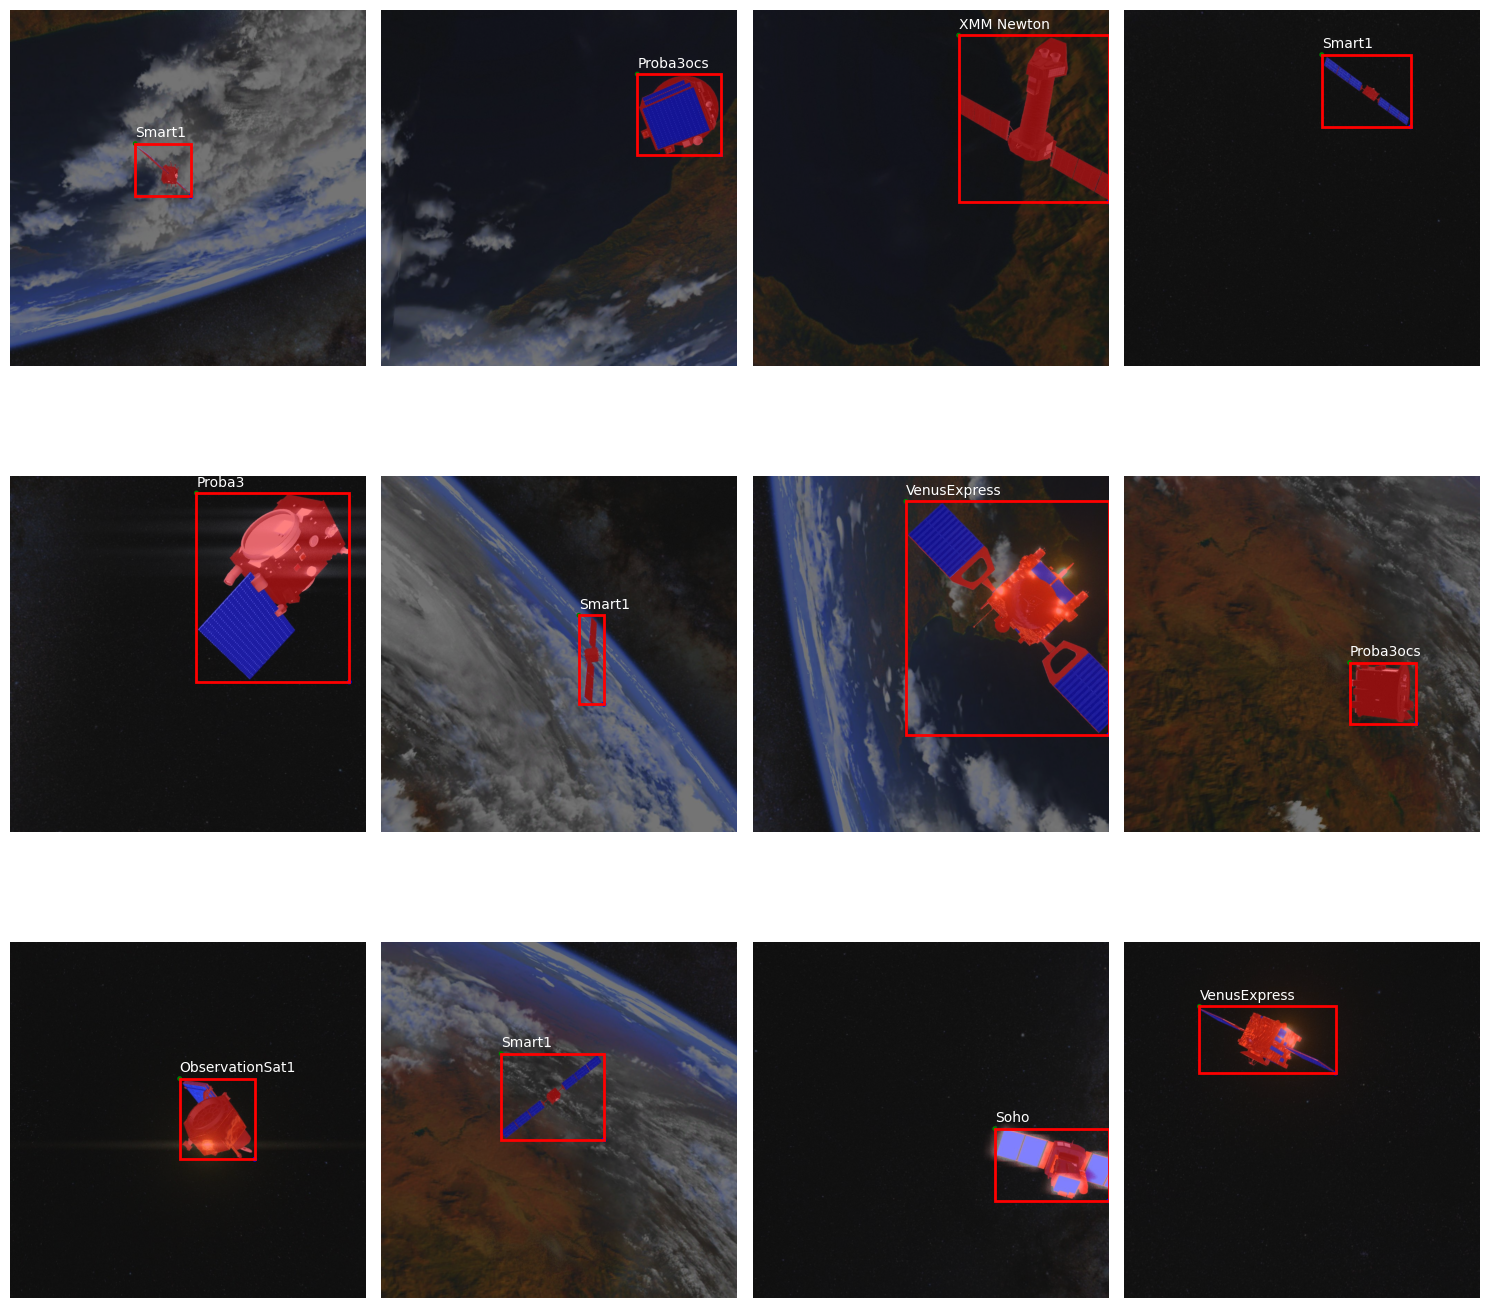

In [ ]:
import random

dataset = SPARKDataset(class_map, root_dir=dataset_root_dir,split=split)
rows = 3
cols = 4

fig, axes = plt.subplots(rows, cols, figsize=(15, 15))

for i in range(rows):
    for j in range(cols):
        dataset.visualize(random.randint(0, 6000),size = (10,10),ax=axes[i][j], mask_visualize=True)
        axes[i][j].axis('off')
fig.tight_layout()

In [ ]:
dataset = PyTorchSPARKDataset(class_map, root_dir=dataset_root_dir, split=split, transform=None)

# 1.1. Negin - EfficDent

In [ ]:
# PyTorch EfficientDet pipeline for SPARK 2024
# - Uses `effdet` (Ross Wightman's EfficientDet) as backbone for detection
# - Adds a custom Mask Head for segmentation (binary masks per detected instance)
# - Provides dataset loader (COCO-like), training loop, evaluation stubs

import os
import pandas as pd
import math
import json
from pathlib import Path
from typing import List, Dict, Tuple, Any

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
from torchvision.ops import boxes as box_ops

# effdet API
try:
    from effdet import create_model
    from effdet.efficientdet import HeadNet
except Exception as e:
    raise ImportError("Please install 'effdet' (pip install effdet) to use this script. Original error: {}".format(e))

# OPTIONAL: use albumentations for augmentations
try:
    import albumentations as A
    from albumentations.pytorch import ToTensorV2
except Exception:
    A = None

# 1.2. Carlos - RT-DETR

# 1.3. Parsa - DINO

In [ ]:
!pip install timm -q

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset, random_split
from torchvision import transforms
import timm

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random


resize everything to 640×640

In [ ]:
IMAGE_SIZE = 240  # as requested

class ResizeToSquare:
    """Resize image & mask to IMAGE_SIZE×IMAGE_SIZE and scale bbox accordingly."""
    def __init__(self, size=IMAGE_SIZE):
        self.size = size

    def __call__(self, sample):
        image = sample['img']
        mask  = sample['mask']
        bbox  = np.array(sample['bbox'], dtype=np.float32)  # [x_min, y_min, x_max, y_max]

        h, w = image.shape[:2]
        # resize image & mask
        image_resized = cv2.resize(image, (self.size, self.size), interpolation=cv2.INTER_LINEAR)
        mask_resized  = cv2.resize(mask, (self.size, self.size), interpolation=cv2.INTER_NEAREST)

        # scale bbox
        scale_x = self.size / w
        scale_y = self.size / h
        bbox[[0, 2]] *= scale_x
        bbox[[1, 3]] *= scale_y

        sample['img'] = image_resized
        sample['mask'] = mask_resized
        sample['bbox'] = bbox.tolist()
        return sample


create a PyTorch dataset for the train split using this transform

In [ ]:
resize_transform = ResizeToSquare(IMAGE_SIZE)

full_train_dataset = PyTorchSPARKDataset(
    class_map=class_map,
    root_dir=dataset_root_dir,
    split='train',
    transform=resize_transform
)

len(full_train_dataset)


60000

Subsample 5000 images and build DataLoaders

In [ ]:
NUM_SAMPLES = 5000
random.seed(42)

indices = random.sample(range(len(full_train_dataset)), NUM_SAMPLES)
subset_dataset = Subset(full_train_dataset, indices)

# 80% train / 20% val
train_size = int(0.8 * NUM_SAMPLES)
val_size   = NUM_SAMPLES - train_size
train_dataset, val_dataset = random_split(subset_dataset, [train_size, val_size])

BATCH_SIZE = 4  # 640×640 + ViT is heavy; keep this small

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=2, pin_memory=True)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")


NameError: name 'Subset' is not defined

DINO-based detector (backbone + heads)

In [ ]:
id2class = {v: k for k, v in class_map.items()}

class DINODetector(nn.Module):
    def __init__(self, num_classes, backbone_name='vit_small_patch16_224.dino'):
        super().__init__()
        # num_classes=0 -> returns features instead of ImageNet classifier
        # dynamic_img_size=True lets us use 640×640 instead of the default 224×224
        self.backbone = timm.create_model(
            backbone_name,
            pretrained=True,
            num_classes=0,
            dynamic_img_size=True  # <-- key line
        )

        embed_dim = self.backbone.num_features

        self.class_head = nn.Linear(embed_dim, num_classes)
        self.bbox_head = nn.Sequential(
            nn.Linear(embed_dim, embed_dim),
            nn.ReLU(inplace=True),
            nn.Linear(embed_dim, 4)
        )

    def forward(self, x):
        feats = self.backbone(x)          # [B, embed_dim]
        logits = self.class_head(feats)   # [B, num_classes]
        bbox   = torch.sigmoid(self.bbox_head(feats))  # [B,4] in [0,1]
        return logits, bbox


    def forward(self, x):
        feats = self.backbone(x)          # [B, embed_dim], global pooled features
        logits = self.class_head(feats)   # [B, num_classes]
        bbox   = torch.sigmoid(self.bbox_head(feats))  # [B,4] in [0,1]
        return logits, bbox

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

num_classes = len(class_map)
model = DINODetector(num_classes=num_classes).to(device)

# DINO / ImageNet normalization
dino_normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std =[0.229, 0.224, 0.225]
)


Using device: cuda


Training loop (classification + bbox regression)

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
criterion_cls  = nn.CrossEntropyLoss()
criterion_bbox = nn.SmoothL1Loss()

LAMBDA_BBOX = 5.0   # weight of bbox loss
NUM_EPOCHS  = 3

def train_one_epoch(epoch):
    model.train()
    running_loss = 0.0

    for batch in train_loader:
        imgs   = batch['img'].to(device)                # [B,3,H,W] in [0,1]
        labels = batch['class'].to(device)              # [B]
        boxes  = batch['bbox'].float().to(device)       # [B,4] in pixels

        # normalize bbox to [0,1]
        target_boxes = boxes / IMAGE_SIZE

        # DINO normalization
        imgs_norm = dino_normalize(imgs)

        optimizer.zero_grad()
        logits, pred_boxes = model(imgs_norm)

        loss_cls  = criterion_cls(logits, labels)
        loss_box  = criterion_bbox(pred_boxes, target_boxes)
        loss      = loss_cls + LAMBDA_BBOX * loss_box

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"[Epoch {epoch+1}] Train loss: {epoch_loss:.4f}")
    return epoch_loss


def evaluate():
    model.eval()
    total_loss = 0.0
    correct = 0
    n_samples = 0

    with torch.no_grad():
        for batch in val_loader:
            imgs   = batch['img'].to(device)
            labels = batch['class'].to(device)
            boxes  = batch['bbox'].float().to(device)

            target_boxes = boxes / IMAGE_SIZE
            imgs_norm = dino_normalize(imgs)

            logits, pred_boxes = model(imgs_norm)
            loss_cls  = criterion_cls(logits, labels)
            loss_box  = criterion_bbox(pred_boxes, target_boxes)
            loss      = loss_cls + LAMBDA_BBOX * loss_box

            total_loss += loss.item() * imgs.size(0)

            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            n_samples += labels.size(0)

    val_loss = total_loss / len(val_loader.dataset)
    val_acc  = correct / n_samples
    print(f"          Val loss: {val_loss:.4f} | Val acc: {val_acc:.4f}")
    return val_loss, val_acc


for epoch in range(NUM_EPOCHS):
    train_one_epoch(epoch)
    evaluate()


KeyboardInterrupt: 

VIS

In [ ]:
model.eval()

def show_prediction(idx=None):
    if idx is None:
        idx = random.randint(0, len(val_dataset)-1)

    sample = val_dataset[idx]
    img = sample['img'].unsqueeze(0).to(device)  # [1,3,H,W]
    label = sample['class'].item()
    gt_box = sample['bbox'].numpy()             # in pixels

    img_norm = dino_normalize(img)
    with torch.no_grad():
        logits, pred_box = model(img_norm)

    pred_cls = logits.argmax(dim=1).item()
    pred_box = (pred_box[0].cpu().numpy() * IMAGE_SIZE)  # back to pixels
    pred_box = np.clip(pred_box, 0, IMAGE_SIZE)

    # unpack
    x1_p, y1_p, x2_p, y2_p = pred_box
    x1_g, y1_g, x2_g, y2_g = gt_box

    img_np = img[0].cpu().permute(1,2,0).numpy()
    fig, ax = plt.subplots(figsize=(6,6))
    ax.imshow(img_np)

    # GT box in red
    rect_gt = patches.Rectangle((x1_g, y1_g), x2_g - x1_g, y2_g - y1_g,
                                linewidth=2, edgecolor='r', facecolor='none', label='GT')
    ax.add_patch(rect_gt)

    # Pred box in lime
    rect_pr = patches.Rectangle((x1_p, y1_p), x2_p - x1_p, y2_p - y1_p,
                                linewidth=2, edgecolor='lime', facecolor='none', label='Pred')
    ax.add_patch(rect_pr)

    ax.set_title(f"GT: {id2class[label]} | Pred: {id2class[pred_cls]}")
    ax.legend()
    ax.axis('off')
    plt.show()

show_prediction()


# 1.4. Tanaz - YOLO

In [ ]:
! git clone https://github.com/ultralytics/ultralytics.git

Cloning into 'ultralytics'...
remote: Enumerating objects: 73465, done.
remote: Counting objects: 100% (103/103), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 73465 (delta 74), reused 56 (delta 56), pack-reused 73362 (from 3)
Receiving objects: 100% (73465/73465), 39.31 MiB | 22.55 MiB/s, done.
Resolving deltas: 100% (55176/55176), done.


In [ ]:
! pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 50.5 MB/s eta 0:00:00


In [ ]:
! pip install supervision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.4/212.4 kB 12.1 MB/s eta 0:00:00


## Imports

In [ ]:
from ultralytics import YOLO
import albumentations
import supervision as sv
import pandas as pd
import os
from PIL import Image
import glob
import shutil

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## Data convert

In [ ]:
# Augmentory
! git clone https://github.com/Smartory/Augmentory.git

In [ ]:
## Utils
def visualise_bbox(img, pts, width, height, colors):
    """cv2 image show with bounding box and class

    Args:
        img: cv2 image
        pts: nd list of bounding box coordinations + class
        width: image width
        height: image height
        colors: class colors (random)
    """
    font = cv2.FONT_HERSHEY_SIMPLEX
    for i in range(len(pts)):
        end_point = (int(round((float(pts[i][0])+float(pts[i][2])/2) * width)),
                     int(round((float(pts[i][1])+float(pts[i][3])/2) * height)))
        start_point = (int(round((float(pts[i][0])-float(pts[i][2])/2) * width)),
                       int(round((float(pts[i][1])-float(pts[i][3])/2) * height)))
        color = tuple(map(int, colors[int(pts[i][4])]))
        print(start_point, end_point)

        cv2.rectangle(img, start_point, end_point, color=color, thickness=1)
        cv2.putText(img, str(pts[i][4]), end_point, font, 1, color, 2)

    cv2_imshow(img)
    # cv2.waitKey(0)  # press any key


def visualise_polygon(img, pts, labels, colors):
    """cv2 image show with polygon and class

    Args:
        img: cv2 image
        pts: nd list of polygon coordinations
        labels: list of polygons classes
        colors: class colors (random)
    """
    font = cv2.FONT_HERSHEY_SIMPLEX
    for i, mask_pts in enumerate(pts):
        mask_pts = np.array(mask_pts, np.int32)
        mask_pts = mask_pts.reshape((-1, 1, 2))
        color = tuple(map(int, colors[int(labels[i])]))
        img = cv2.polylines(img, [mask_pts], True, color=color, thickness=3)
        cv2.putText(img, labels[i], mask_pts[0][0], font, 1, color, 2)
    cv2_imshow(img)
    # cv2.waitKey(0)  # press any key


def mask2poly(folder_path, filename, image, save_path, mask_path=""):
    """converts masks to polygons in yolo format and save in txt file

    Args:
        folder_path: root directory of dataset
        filename: name of image and correspondent txt file
        image: cv2 image
        save_path: directory of new polygons txt
        masks: nd list of masks
        labels: list of labels (for instance segmentation)
        mask_path: directory of saved masks (if you want to read masks from directory)
    """
    width = image.shape[1]
    height = image.shape[0]
    label = ""
    class_colors = {
    "class_1": (255, 0, 0),   # red
    "class_3": (0, 0, 255),   # blue
    }
    # print(image.shape)
    polygon_filename = folder_path + save_path + filename + ".txt"
    polygon_file = open(polygon_filename, "w")
    # if you want to read masks from directory uncomment the following comments and modify the code
    # based on your mask format
    m = cv2.imread(folder_path + mask_path + filename + ".jpg")

    # ADDED: Split the mask into RGB channels
    # OpenCV reads images as BGR, so we need to convert or reorder
    # Option 1: Convert to RGB first
    m_rgb = cv2.cvtColor(m, cv2.COLOR_BGR2RGB)

    # Get each channel as binary mask
    red_channel = m_rgb[:, :, 0]   # R channel
    blue_channel = m_rgb[:, :, 2]  # B channel

    # Process each channel separately
    for channel_idx, (channel, channel_name) in enumerate([
        (red_channel, "class_1"),
        (blue_channel, "class_2")
    ]):
        # Create binary mask from this channel (non-zero pixels become 1)
        binary_mask = (channel >= 128).astype(np.uint8) * 255

        mask_filename = f"{filename}_{channel_name}_binary.png"
        mask_filepath = os.path.join(folder_path + save_path, mask_filename)
        cv2.imwrite(mask_filepath, binary_mask)

        # Only process if there are any non-zero pixels
        if np.any(binary_mask):
            # Get label for this class
            label = channel_idx  # 0 for class_1, 1 for class_2

            # Convert mask to polygons
            poly = sv.mask_to_polygons(binary_mask)

            # Write to file
            for p in poly:
                polygon_file.write(str(label) + " ")
                for i in range(0, len(p)):
                    polygon_file.write(str(round(float(p[i][0]/width),6)) + " " +
                                        str(round(float(p[i][1]/height),6)) + " ")
                polygon_file.write("\n")

    polygon_file.close()
    return

In [ ]:
# For segmentation: convert mask to polygon
folder = "/content/yolo_dataset_balanced/"
images = "images/val/"
labels = "labels/val/"
masks = "masks/val/"
# file_name = "000000000074"
class_number = 10
colors = []
i = 0
# for i in range(class_number):
#     colors.append(tuple(np.random.choice(range(256), size=3)))
for filename in os.listdir(folder + images):
    name = filename[:-4]
    print(name)
    # if name == file_name:
    #     continue
    img = cv2.imread(folder + images + filename)
    # if not os.path.isfile(folder + labels + name + ".txt"):
    #     continue
    # f1 = open(folder + labels + name + ".txt", "r")
    # Lines = f1.readlines()
    # p = []
    # for l in Lines:
    #     l = l.split()
    #     new_l = list(l[1:])
    #     new_l.insert(4, l[0])
    #     p.append(new_l)
    # p = np.array(p)
    # print(p, img.shape,)
    # visualise_bbox(img, p, img.shape[1], img.shape[0], colors)

    mask2poly(folder, name, img, 'results/', mask_path = masks)
    i += 1
    if i ==5:
        break

Proba3_image_07583_img
Smart1_image_05983_img
XMM Newton_image_05305_img
Proba2_image_03949_img
Proba2_image_07979_img


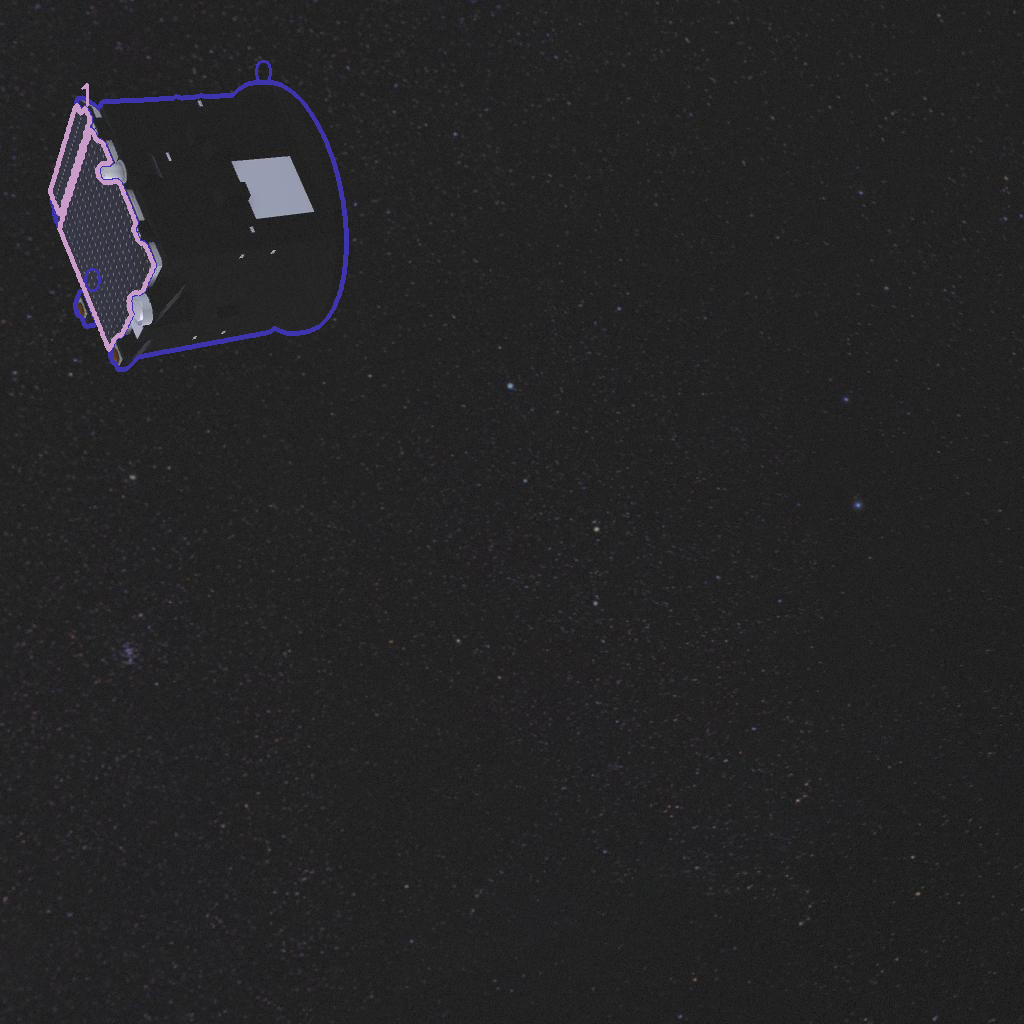

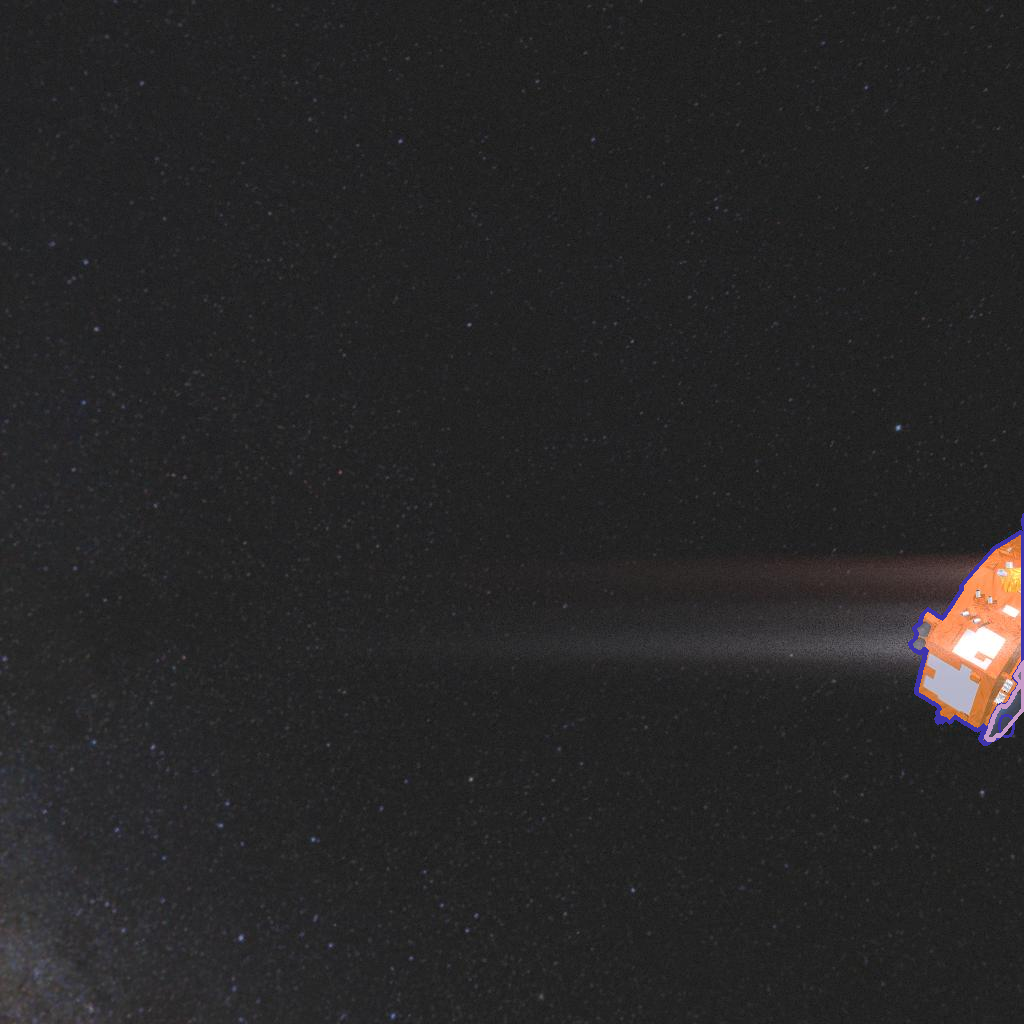

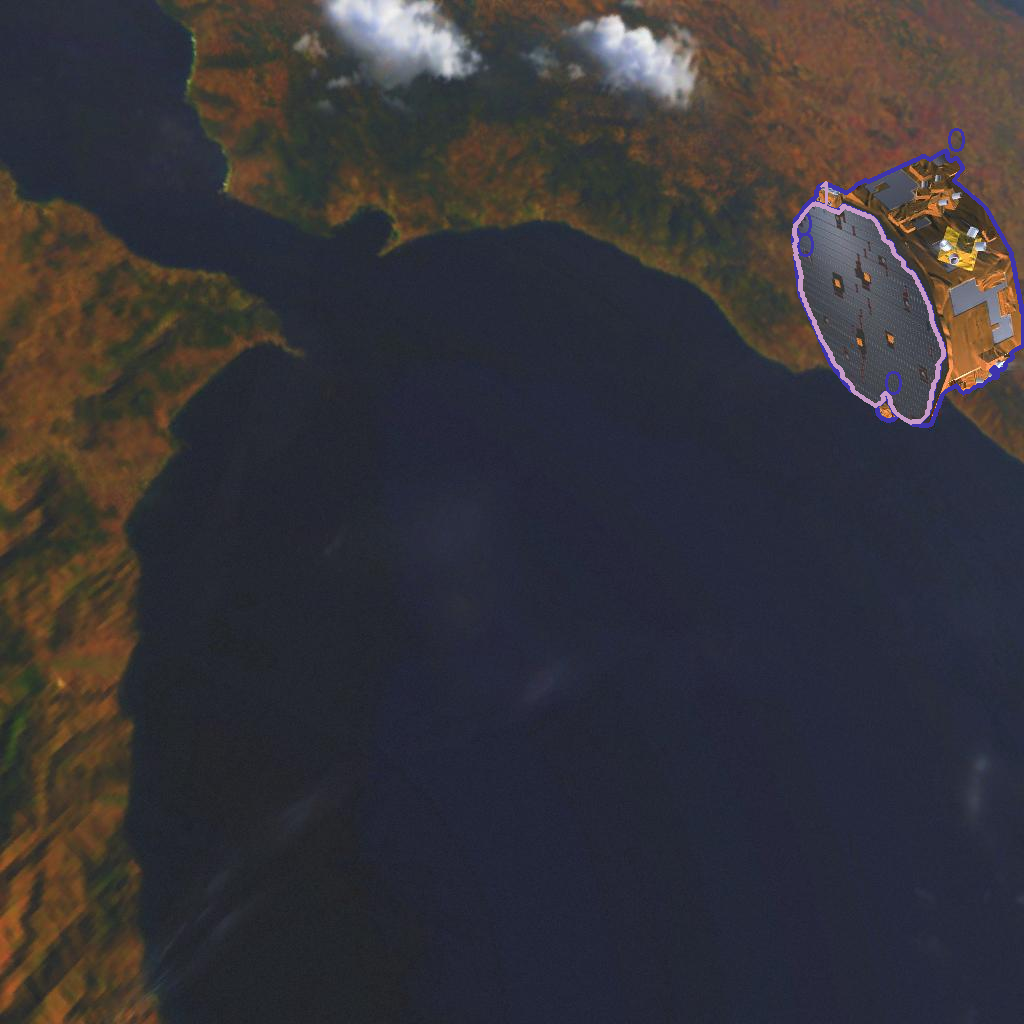

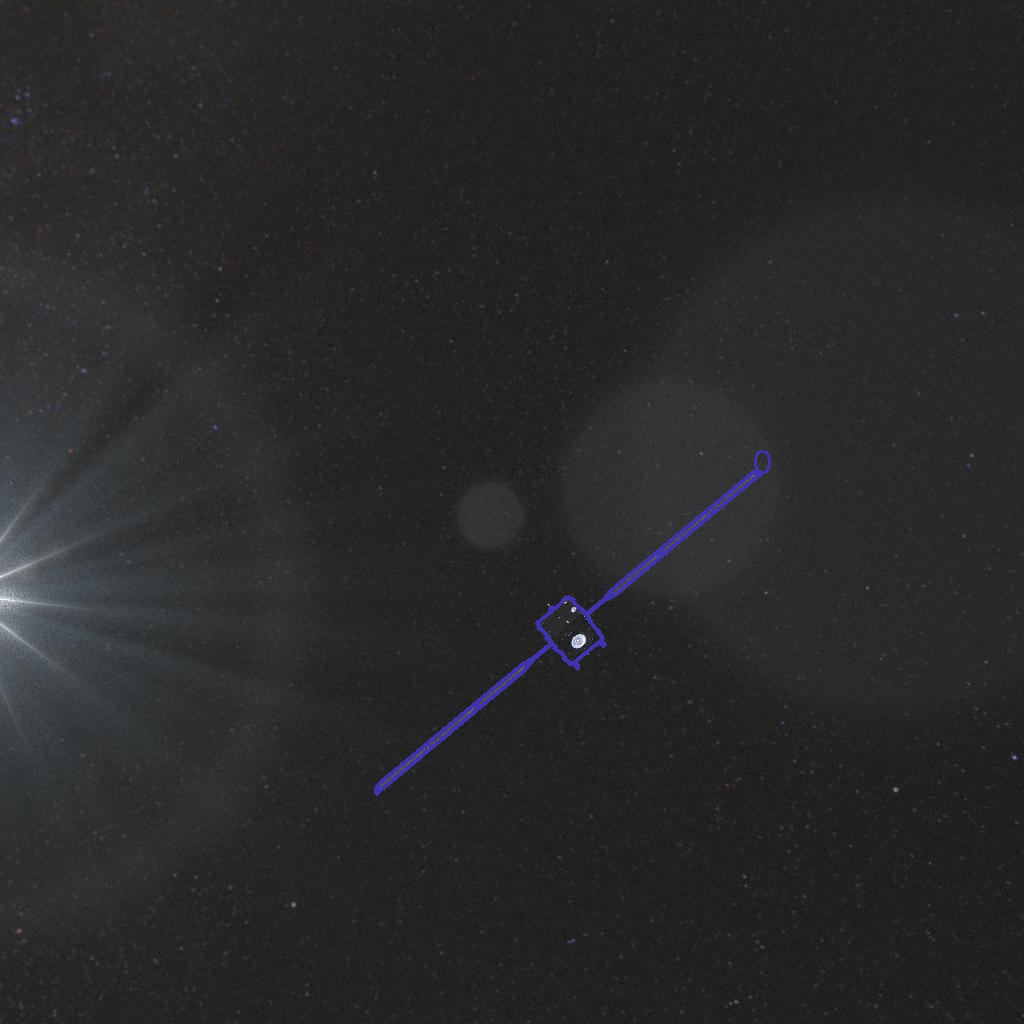

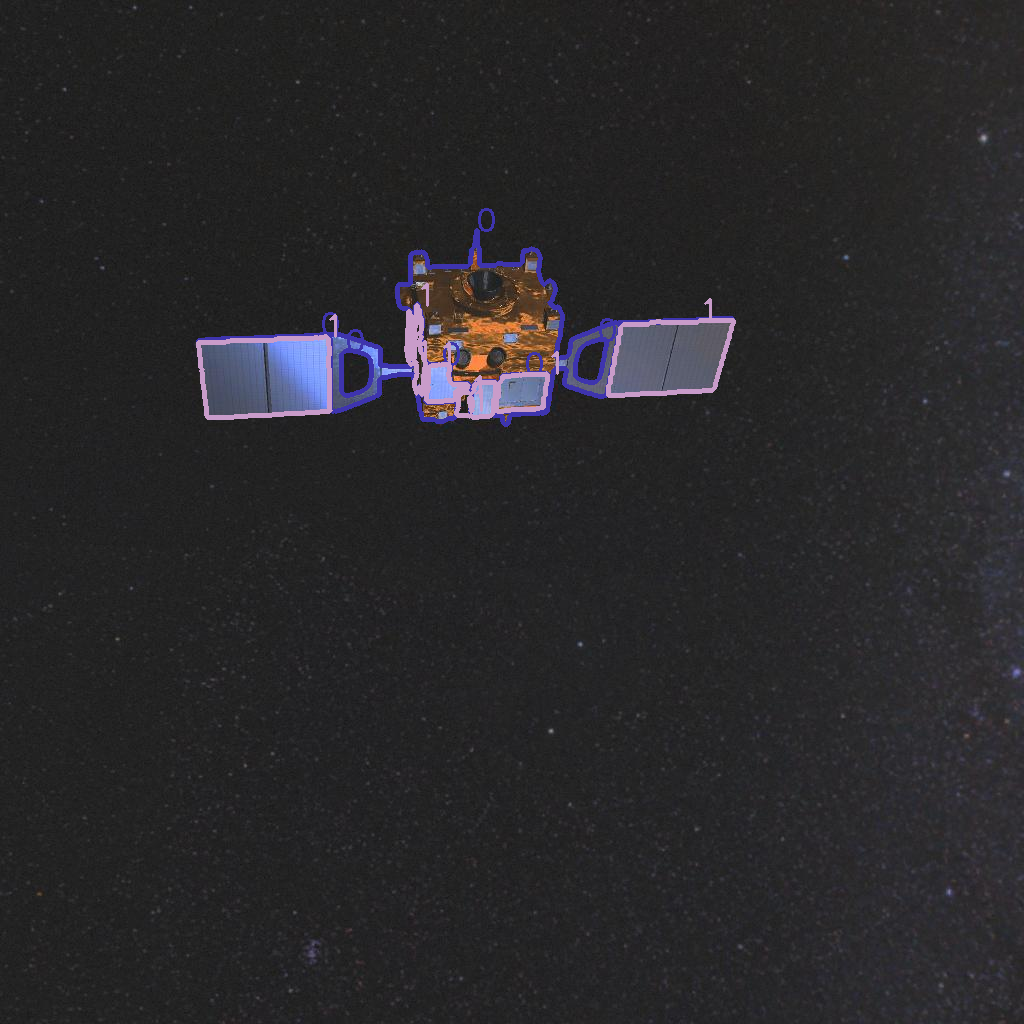

In [ ]:
# For segmentation: convert mask to polygon
folder = "/content/yolo_dataset_balanced/"
images = "images/val/"
labels = "results/"
masks = "masks/val/"
# file_name = "000000000074"
class_number = 2
colors = []
for i in range(class_number):
    colors.append(tuple(np.random.choice(range(256), size=3)))
for filename in os.listdir(folder + images):
    name = filename[:-4]
    # print(name)
    # if name == file_name:
    #     continue
    img = cv2.imread(folder + images + filename)
    if not os.path.isfile(folder + labels + name + ".txt"):
        continue
    f1 = open(folder + labels + name + ".txt", "r")
    Lines = f1.readlines()
    p = []
    label = []
    for l in Lines:
        # print(l)
        label.append(l.split()[0])
        temp = list(l.split()[1:])
        # print(temp)
        temp2 = []
        for i in range(0,len(temp)-1,2):
            temp2.append([int(round(float(temp[i])*img.shape[1])), int(round(float(temp[i+1])*img.shape[0]))])
        p.append(temp2)
    visualise_polygon(img, p, label, colors)

## Preprocess

In [ ]:
# Negin
def convert_to_yolo_format_balanced(csv_path, base_images_dir, output_dataset_dir, train=True, samples_per_class=500):
    """
    Convert dataset to YOLO format with balanced class distribution

    Args:
        csv_path: Path to CSV file with annotations
        base_images_dir: Original images directory
        output_dataset_dir: New directory for YOLO-formatted dataset
        train: Whether processing training or validation data
        samples_per_class: Number of images to sample per class
    """
    # Read CSV file
    df = pd.read_csv(csv_path)

    # Get all spacecraft folders
    # spacecraft_folders = ['Cheops', 'LisaPathfinder', 'ObservationSat1', 'Proba2', 'Proba3',
    #     'Proba3ocs', 'Smart1', 'Soho', 'VenusExpress', 'XMM Newton']

    class_mapping = {'Cheops': 0, 'LisaPathfinder': 1, 'ObservationSat1': 2, 'Proba2': 3, 'Proba3': 4,
                     'Proba3ocs': 5, 'Smart1': 6, 'Soho': 7, 'VenusExpress': 8, 'XMM Newton': 9}

    # Create YOLO directory structure
    if train:
        split = "train"
    else:
        split = "val"

    # Create output directories
    output_images_dir = os.path.join(output_dataset_dir, "images", split)
    output_labels_dir = os.path.join(output_dataset_dir, "labels", split)
    output_mask_dir = os.path.join(output_dataset_dir, "masks", split)
    os.makedirs(output_images_dir, exist_ok=True)
    os.makedirs(output_labels_dir, exist_ok=True)
    os.makedirs(output_mask_dir, exist_ok=True)

    # Group data by class and sample 500 images per class
    class_groups = {}
    for class_name in class_mapping.keys():
        class_data = df[df['Class'] == class_name]
        class_groups[class_name] = class_data

    # Sample 500 images from each class
    sampled_data = []
    for class_name, class_df in class_groups.items():
        if len(class_df) >= samples_per_class:
            # Randomly sample if we have enough images
            sampled_class = class_df.sample(n=samples_per_class, random_state=42)
        else:
            # If not enough images, use all available and warn
            print(f"Warning: Class {class_name} has only {len(class_df)} images, using all available")
            sampled_class = class_df
        sampled_data.append(sampled_class)

    # Combine all sampled data
    balanced_df = pd.concat(sampled_data, ignore_index=True)

    # Shuffle the balanced dataset
    balanced_df = balanced_df.sample(frac=1, random_state=42).reset_index(drop=True)

    processed_count = 0
    skipped_count = 0
    class_counts = {class_name: 0 for class_name in class_mapping.keys()}

    print(balanced_df.head())

    # Process each row in the balanced dataframe
    for index, row in balanced_df.iterrows():
        image_name = row['Image name']
        class_name = row['Class']
        bbox_str = row['Bounding box']

        # Clean and parse bounding box coordinates
        bbox_str = bbox_str.strip('()')
        bbox_coords = [int(coord.strip()) for coord in bbox_str.split(',')]

        x1, y1, x2, y2 = bbox_coords

        image_path = os.path.join(base_images_dir, class_name, split, image_name)
        # Get image dimensions
        with Image.open(image_path) as img:
            img_width, img_height = img.size
        # print(class_name + image_name)
        # print(img_width, img_height)
        # print("before", x1, y1, x2, y2)
        # Convert to YOLO format
        x_center = (x1 + x2) / (2*img_width)
        y_center = (y1 + y2) / (2*img_height)
        width = (x2 - x1) / img_width
        height = (y2 - y1) / img_height
        # print("after", x_center, y_center, width, height)

        # Get class ID
        class_id = class_mapping[class_name]

        # Create unique filename to avoid conflicts
        unique_image_name = f"{class_name}_{image_name}"
        unique_label_name = os.path.splitext(unique_image_name)[0] + '.txt'

        # Copy image to new YOLO structure
        output_image_path = os.path.join(output_images_dir, unique_image_name)
        shutil.copy2(image_path, output_image_path)
        mask_path = os.path.join("spark-2024-train-val/mask/", class_name, split, image_name[:-7]+"layer.jpg")
        output_mask_path = os.path.join(output_mask_dir, unique_image_name)
        shutil.copy2(mask_path, output_mask_path)

        # Create label file in new YOLO structure
        label_path = os.path.join(output_labels_dir, unique_label_name)

        # Write YOLO format to file
        with open(label_path, 'w') as f:
            f.write(f"{class_id} {x_center} {y_center} {width} {height}\n")

        processed_count += 1
        class_counts[class_name] += 1
        image_found = True

    # Print class distribution
    print(f"\nClass distribution for {split} set:")
    for class_name, count in class_counts.items():
        print(f"  {class_name}: {count} images")

    print(f"\nProcessing complete: {processed_count} images processed, {skipped_count} images skipped for {split} set")
    print(f"Total images: {processed_count} (Target: {len(class_mapping) * samples_per_class})")

# Usage
csv_train_path = "/content/spark-2024-train-val/train.csv"
csv_val_path = "/content/spark-2024-train-val/val.csv"

# Original images directory
base_images_dir = "spark-2024-train-val/images/"

# New YOLO dataset directory
output_dataset_dir = "yolo_dataset_balanced"

# Convert training data with balanced sampling
# convert_to_yolo_format_balanced(csv_train_path, base_images_dir, output_dataset_dir, samples_per_class=500, train=True)

# Convert validation data (you might want to balance this too, or keep original distribution)
convert_to_yolo_format_balanced(csv_val_path, base_images_dir, output_dataset_dir, train=False, samples_per_class=100)

            Image name              Mask name      Class          Bounding box
0  image_03474_img.jpg  image_03474_layer.jpg  Proba3ocs  (584, 344, 856, 624)
1  image_08885_img.jpg  image_08885_layer.jpg       Soho  (512, 456, 760, 912)
2  image_09744_img.jpg  image_09744_layer.jpg       Soho   (592, 0, 1024, 184)
3  image_09847_img.jpg  image_09847_layer.jpg     Smart1  (736, 264, 840, 632)
4  image_09085_img.jpg  image_09085_layer.jpg     Proba3   (608, 0, 1000, 424)

Class distribution for val set:
  Cheops: 100 images
  LisaPathfinder: 100 images
  ObservationSat1: 100 images
  Proba2: 100 images
  Proba3: 100 images
  Proba3ocs: 100 images
  Smart1: 100 images
  Soho: 100 images
  VenusExpress: 100 images
  XMM Newton: 100 images

Processing complete: 1000 images processed, 0 images skipped for val set
Total images: 1000 (Target: 1000)


In [ ]:
def convert_to_yolo_format(csv_path, base_images_dir, output_dataset_dir, train=True):
    """
    Convert dataset to YOLO format with balanced class distribution

    Args:
        csv_path: Path to CSV file with annotations
        base_images_dir: Original images directory
        output_dataset_dir: New directory for YOLO-formatted dataset
        train: Whether processing training or validation data
        samples_per_class: Number of images to sample per class
    """
    # Read CSV file
    df = pd.read_csv(csv_path)

    class_mapping = {'Cheops': 0, 'LisaPathfinder': 1, 'ObservationSat1': 2, 'Proba2': 3, 'Proba3': 4,
                     'Proba3ocs': 5, 'Smart1': 6, 'Soho': 7, 'VenusExpress': 8, 'XMM Newton': 9}

    # Create YOLO directory structure
    if train:
        split = "train"
    else:
        split = "val"

    # Create output directories
    output_images_dir = os.path.join(output_dataset_dir, "images", split)
    output_labels_dir = os.path.join(output_dataset_dir, "labels", split)
    os.makedirs(output_images_dir, exist_ok=True)
    os.makedirs(output_labels_dir, exist_ok=True)

    processed_count = 0
    skipped_count = 0
    class_counts = {class_name: 0 for class_name in class_mapping.keys()}

    # Process each row in the balanced dataframe
    for index, row in df.iterrows():
        image_name = row['Image name']
        class_name = row['Class']
        bbox_str = row['Bounding box']

        # Clean and parse bounding box coordinates
        bbox_str = bbox_str.strip('()')
        bbox_coords = [int(coord.strip()) for coord in bbox_str.split(',')]

        x1, y1, x2, y2 = bbox_coords

        image_path = os.path.join(base_images_dir, class_name, split, image_name)
        # Get image dimensions
        with Image.open(image_path) as img:
            img_width, img_height = img.size
        # print(class_name + image_name)
        # print(img_width, img_height)
        # print("before", x1, y1, x2, y2)
        # Convert to YOLO format
        x_center = (x1 + x2) / (2*img_width)
        y_center = (y1 + y2) / (2*img_height)
        width = (x2 - x1) / img_width
        height = (y2 - y1) / img_height
        # print("after", x_center, y_center, width, height)

        # Get class ID
        class_id = class_mapping[class_name]

        # Create unique filename to avoid conflicts
        unique_image_name = f"{class_name}_{image_name}"
        unique_label_name = os.path.splitext(unique_image_name)[0] + '.txt'

        # Copy image to new YOLO structure
        output_image_path = os.path.join(output_images_dir, unique_image_name)
        shutil.copy2(image_path, output_image_path)

        # Create label file in new YOLO structure
        label_path = os.path.join(output_labels_dir, unique_label_name)

        # Write YOLO format to file
        with open(label_path, 'w') as f:
            f.write(f"{class_id} {x_center} {y_center} {width} {height}\n")

        processed_count += 1
        class_counts[class_name] += 1
        image_found = True
        if image_name == "image_03474_img.jpg":
            print(image_name, class_name, class_id, x1, y1, x2, y2, x_center, y_center, width, height)

    # Print class distribution
    print(f"\nClass distribution for {split} set:")
    for class_name, count in class_counts.items():
        print(f"  {class_name}: {count} images")

    print(f"\nProcessing complete: {processed_count} images processed, {skipped_count} images skipped for {split} set")
    print(f"Total images: {processed_count}")

# Usage
csv_train_path = "/content/drive/MyDrive/CVI_Spark/train.csv"
csv_val_path = "/content/drive/MyDrive/CVI_Spark/val.csv"

# Original images directory
base_images_dir = "spark-2024-train-val/images/"

# New YOLO dataset directory
output_dataset_dir = "yolo_dataset"

# Convert training data with balanced sampling
convert_to_yolo_format(csv_train_path, base_images_dir, output_dataset_dir, train=True)

# Convert validation data (you might want to balance this too, or keep original distribution)
convert_to_yolo_format(csv_val_path, base_images_dir, output_dataset_dir, train=False)

image_03474_img.jpg Cheops 0 237 284 495 611 0.357421875 0.43701171875 0.251953125 0.3193359375
image_03474_img.jpg LisaPathfinder 1 573 636 802 963 0.67138671875 0.78076171875 0.2236328125 0.3193359375
image_03474_img.jpg Proba2 3 0 333 630 833 0.3076171875 0.5693359375 0.615234375 0.48828125
image_03474_img.jpg Proba3 4 433 649 981 1023 0.6904296875 0.81640625 0.53515625 0.365234375
image_03474_img.jpg Smart1 6 138 455 678 868 0.3984375 0.64599609375 0.52734375 0.4033203125
image_03474_img.jpg VenusExpress 8 509 58 757 403 0.6181640625 0.22509765625 0.2421875 0.3369140625

Class distribution for train set:
  Cheops: 6000 images
  LisaPathfinder: 6000 images
  ObservationSat1: 6000 images
  Proba2: 6000 images
  Proba3: 6000 images
  Proba3ocs: 6000 images
  Smart1: 6000 images
  Soho: 6000 images
  VenusExpress: 6000 images
  XMM Newton: 6000 images

Processing complete: 60000 images processed, 0 images skipped for train set
Total images: 60000
image_03474_img.jpg Proba3ocs 5 582 346

In [ ]:
! rm -r /content/yolo_dataset

In [ ]:
!zip -r data.zip /content/yolo_dataset/labels

Streaming output truncated to the last 5000 lines.
updating: content/yolo_dataset/labels/val/Proba3_image_06701_img.txt (deflated 20%)
updating: content/yolo_dataset/labels/val/Proba3_image_07908_img.txt (deflated 18%)
updating: content/yolo_dataset/labels/val/Proba3ocs_image_09612_img.txt (deflated 16%)
updating: content/yolo_dataset/labels/val/Soho_image_03292_img.txt (deflated 17%)
updating: content/yolo_dataset/labels/val/Cheops_image_07249_img.txt (deflated 12%)
updating: content/yolo_dataset/labels/val/ObservationSat1_image_06958_img.txt (deflated 29%)
updating: content/yolo_dataset/labels/val/XMM Newton_image_06465_img.txt (deflated 18%)
updating: content/yolo_dataset/labels/val/Proba2_image_08527_img.txt (deflated 16%)
updating: content/yolo_dataset/labels/val/ObservationSat1_image_04627_img.txt (deflated 13%)
updating: content/yolo_dataset/labels/val/Soho_image_02993_img.txt (deflated 14%)
updating: content/yolo_dataset/labels/val/VenusExpress_image_07846_img.txt (deflated 17%

In [ ]:
! cd ultralytics/

## Train

In [ ]:
model = YOLO('yolo11m.pt')
model.train(data='/content/data.yaml', batch=16, epochs=150, imgsz=640, patience=50, name='test_train')

Ultralytics 8.3.232 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=test_train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=50, perspective=0.0, plots=True, pose=12.0, 

In [ ]:
! yolo task=detect mode=train model=yolo11n.pt data="/content/data.yaml" epochs=150 imgsz=640 batch=64 patience=50 name='test_train'

Traceback (most recent call last):
  File "/usr/local/bin/yolo", line 8, in <module>
    sys.exit(entrypoint())
             ^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/cfg/__init__.py", line 955, in entrypoint
    model = YOLO(model, task=task)
            ^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/models/yolo/model.py", line 81, in __init__
    super().__init__(model=model, task=task, verbose=verbose)
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/engine/model.py", line 149, in __init__
    self._load(model, task=task)
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/engine/model.py", line 288, in _load
    self.model, self.ckpt = load_checkpoint(weights)
                            ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/nn/tasks.py", line 1461, in load_checkpoint
    ckpt, weight = torch_safe_load(weight)  # load ckpt
                   ^^^^^^^^^